# Matched-matrix LoRA: does a LoRA placed where LoRAs are placed commute as well as a full-weight fine-tune?

Round 5 (`experiments/lora_matched`, 2026-10-19). Round 4 put a LoRA on one matrix the decomposition barely reads and compared it with a
fine-tune on all 24 matrices, so it could not separate the LoRA from its site. Here a rank-8 LoRA sits on all 24 decomposed matrices (the
standard placement) and goes through the same Euclidean lift as the full-weight fine-tune, in the same job, on an L40. Report:
`reports/2026-10-19_analysis_lora-matched.md`; predictions `results/predictions.json` (filed before the run); design
`reports/2026-10-19_review_lora-failure-and-fixes.md` section 3.2.

**Terms.** *Lift*: the finished weight change written as the minimum-norm change (dU, dV) to each matrix's alive subcomponents; what no
first-order change can express goes to Δ. *Do-nothing*: δW placed in Δ, subcomponents untouched. *Inexpressible share*: the share of the
update's input-weighted output energy that no first-order change of the alive subcomponents can express; its *isotropic null* is that share
for a random update of the same matrix; a *saturated* matrix (4 of 24) has null 0 whatever the update; *pooled* = energy-weighted over the 20
non-saturated matrices. *Route split*: the held-out log-odds gain of `o` at the trigger split into d (changed subcomponents at W₀'s CI values),
r (changed CI values on the unchanged subcomponents), i, e_gate (masked off) and e_Δ (not in the subcomponents at all). *Pile ratios*: round 2's
harness (2 × 128 Pile val rows; stochastic, CI-masked, PGD KL), each ÷ W₀'s under the same adversary seed. *Scored step*: the first LoRA
checkpoint with held-out P(o) ≥ 0.9.

In [1]:
import json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

R = Path('../experiments/lora_matched/results')
res = json.loads((R / 'lora_matched.json').read_text())
pred = json.loads((R / 'predictions.json').read_text())
S, FT, L0, L1, SC, W0, REF = res['sizes'], res['ft'], res['lora_s0'], res['lora_s1'], res['score'], res['W0'], res['ref']
FLOOR = 1 + 3 * W0['pgd_floor']           # Pile PGD: W0 + 3 floors (3-seed spread)
C = {'blue': '#2a78d6', 'orange': '#eb6834', 'aqua': '#1baf7a', 'yellow': '#eda100', 'green': '#008300', 'gray': '#8a8a86'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.titlesize': 11, 'font.size': 9, 'legend.fontsize': 8})

rows = []
def add(name, rec, ev, step, inex):
    s, pc = rec['routes']['shares'], rec['routes']['p_cells']
    rows.append({'arm': name, 'step': step, 'P(o)': ev['p_o'], 'kl_other': ev['kl_other'], 'rel norm max': rec['rel_norm_max'],
                 'gain': rec['routes']['gain'], 'P(o) components only': pc['U1'], 'd': s['d'], 'r': s['r'], 'i': s['i'],
                 'e_gate': s['e_gate'], 'e_delta': s['e_delta'], 'inexpressible': inex['pooled'], 'null': inex['pooled_null'],
                 'Delta change': rec['delta_change_frac'],
                 **({f'pile {k}': rec['pile'][k] for k in ('stochastic_kl', 'ci_masked_kl', 'pgd_kl')} if 'pile' in rec else {})})

m = FT['measured']
add('ft nothing', m['nothing'], FT['evals'][str(FT['step'])], FT['step'], m['inexpressible'])
add('ft lift', m['lift'], FT['evals'][str(FT['step'])], FT['step'], m['inexpressible'])
for name, a in (('LoRA', L0), ('LoRA s1', L1)):
    for step in sorted(a['steps'], key=int):
        st, ev = a['steps'][step], a['evals'][step]
        add(f'{name} nothing', st['nothing'], ev, int(step), st['inexpressible'])
        add(f'{name} lift', st['lift'], ev, int(step), st['inexpressible'])
T = pd.DataFrame(rows)
scored = T[(T.arm.str.startswith('ft')) | ((T.arm.str.startswith('LoRA')) & (T.step == L0['scored_step']))].reset_index(drop=True)
print(f"W0 PGD floor f = {W0['pgd_floor']:.3f} (seeds {[round(v['pgd_kl'], 3) for v in W0['pile'].values()]}); W0 + 3 floors = {FLOOR:.2f}; m = {SC['G0']['m']}")
print('gates:', {k: SC[k] for k in ('G1', 'G4')}, '|', SC['verdict'])
T.round(3)

W0 PGD floor f = 0.209 (seeds [0.692, 0.836, 0.705]); W0 + 3 floors = 1.63; m = 0.1
gates: {'G1': {'ft': True, 'lora_s0': True, 'lora_s1': True}, 'G4': {'lift_ft_pgd_ratio': 5.407528888504781, 'nothing_ft_pgd_ratio': 2.183179226410663, 'ok': {'lift_ft_pgd_ratio': True, 'nothing_ft_pgd_ratio': True}}} | gates ok


,arm,step,P(o),kl_other,rel norm max,gain,P(o) components only,d,r,i,e_gate,e_delta,inexpressible,null,Delta change,pile stochastic_kl,pile ci_masked_kl,pile pgd_kl
0,ft nothing,10,0.999,0.055,0.011,13.430,0.012,0.000,0.597,0.000,-0.597,1.000,0.268,0.531,1.000,1.001,0.997,2.183
1,ft lift,10,0.999,0.055,0.011,13.430,0.998,0.052,0.597,0.001,0.260,0.090,0.268,0.531,0.360,1.001,0.996,5.408
2,LoRA nothing,2,0.961,0.059,0.021,9.738,0.012,0.000,0.608,0.000,-0.608,1.000,0.478,0.553,1.000,1.003,1.007,1.166
3,LoRA lift,2,0.961,0.059,0.021,9.738,0.868,0.023,0.608,0.029,0.122,0.218,0.478,0.553,0.398,1.003,1.006,1.128
4,LoRA nothing,100,1.000,0.011,0.057,14.239,0.012,0.000,0.561,0.000,-0.561,1.000,0.550,0.674,1.000,NaN,NaN,NaN
5,LoRA lift,100,1.000,0.011,0.057,14.239,0.998,0.013,0.561,0.032,0.287,0.107,0.550,0.674,0.464,NaN,NaN,NaN
6,LoRA s1 nothing,2,0.952,0.052,0.020,9.591,0.012,0.000,0.618,0.000,-0.618,1.000,0.409,0.528,1.000,NaN,NaN,NaN
7,LoRA s1 lift,2,0.952,0.052,0.020,9.591,0.861,0.024,0.618,0.010,0.136,0.212,0.409,0.528,0.403,NaN,NaN,NaN
8,LoRA s1 nothing,100,0.983,0.008,0.059,9.574,0.012,0.000,0.619,0.000,-0.619,1.000,0.662,0.595,1.000,NaN,NaN,NaN
9,LoRA s1 lift,100,0.983,0.008,0.059,9.574,0.934,0.029,0.619,0.014,0.170,0.167,0.662,0.595,0.459,NaN,NaN,NaN


Every arm learned (G1): the LoRA passes P(o) ≥ 0.9 at step 2 for both seeds (0.961, 0.952), at the same off-target cost as the fine-tune
at step 10 (kl_other 0.059 and 0.052 against 0.055) and twice its relative update norm. G2 holds for every lift. **G4 closed:** the
fine-tune's do-nothing and lift Pile PGD ratios on the L40 read 2.183 and 5.408 against round 2's 2.18 and 5.41, with round 4's measurement
code moved unchanged into `src/commute/harness.py`; round 4's 2.49 and 7.31 were the 4090's adversarial search. The W₀ PGD floor on the
L40 is 21% over three seeds (round 4 on the 4090: 3.5%), so "within 3 floors" is ≤ 1.63 here.

## 1. Could it do it? Faithfulness of each state under VPD's own checks (the weak version's first half)

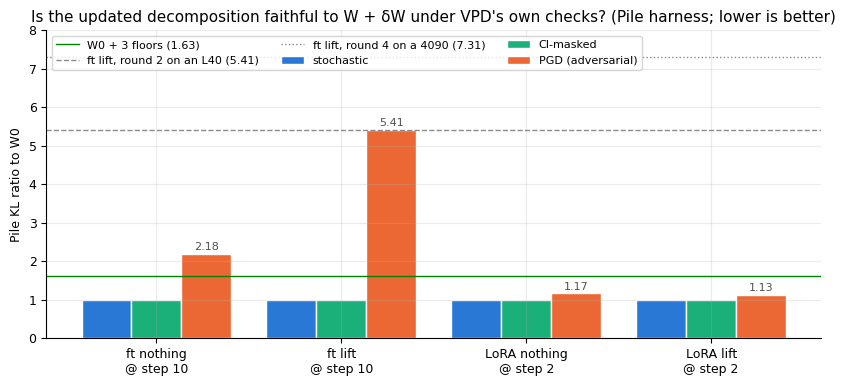

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
P = scored[scored['pile pgd_kl'].notna()].reset_index(drop=True)
x = np.arange(len(P)); w = 0.27
for j, (k, col, lab) in enumerate((('pile stochastic_kl', C['blue'], 'stochastic'), ('pile ci_masked_kl', C['aqua'], 'CI-masked'), ('pile pgd_kl', C['orange'], 'PGD (adversarial)'))):
    ax.bar(x + (j - 1) * w, P[k], w, color=col, label=lab, edgecolor='white', linewidth=1)
ax.axhline(FLOOR, color=C['green'], lw=1, label=f'W0 + 3 floors ({FLOOR:.2f})')
ax.axhline(REF['lift_ft_pgd_ratio'], color=C['gray'], lw=1, ls='--', label=f"ft lift, round 2 on an L40 ({REF['lift_ft_pgd_ratio']})")
ax.axhline(REF['round4_4090']['lift_ft_pgd_ratio'], color=C['gray'], lw=1, ls=':', label=f"ft lift, round 4 on a 4090 ({REF['round4_4090']['lift_ft_pgd_ratio']})")
for i, v in enumerate(P['pile pgd_kl']):
    ax.text(x[i] + w, v + 0.1, f'{v:.2f}', ha='center', fontsize=8, color='#52514e')
ax.set_xticks(x); ax.set_xticklabels([f'{a}\n@ step {s}' for a, s in zip(P.arm, P.step)])
ax.set_ylabel('Pile KL ratio to W0'); ax.set_ylim(0, 8)
ax.set_title("Is the updated decomposition faithful to W + δW under VPD's own checks? (Pile harness; lower is better)")
ax.legend(ncol=3, loc='upper left'); plt.show()

**Could it do it?** Yes for the LoRA at the step it learns, no for the fine-tune. The lifted LoRA decomposition sits at the W₀ floor on
every Pile check (PGD 1.13; its do-nothing placement 1.17), where the fine-tune's lift at step 10 reads 5.41 (do-nothing 2.18). Stochastic
and CI-masked ratios are 0.996–1.007 for every arm, as in every round.

**Does it match the prediction?** No. C2m was filed as "the LoRA lift reads ≥ 5, fragile like the fine-tune's" (the reasoning: round 4's
fragility grew with how much was lifted). The filed null, "≤ 2 and e_Δ ≤ 0.2", is missed by e_Δ = 0.218, so the score is "neither" by
the letter and reversed in direction. **Not like for like yet:** the LoRA was scored at step 2, where round 2 found the fine-tune's own lift at
the floor too (1.14 at step 1, rising to 5.41 by step 10); the LoRA lift's Pile numbers at steps 10 and 100 were not run (section 4).

## 2. Reading A, second half: how much of each update does Δ absorb?

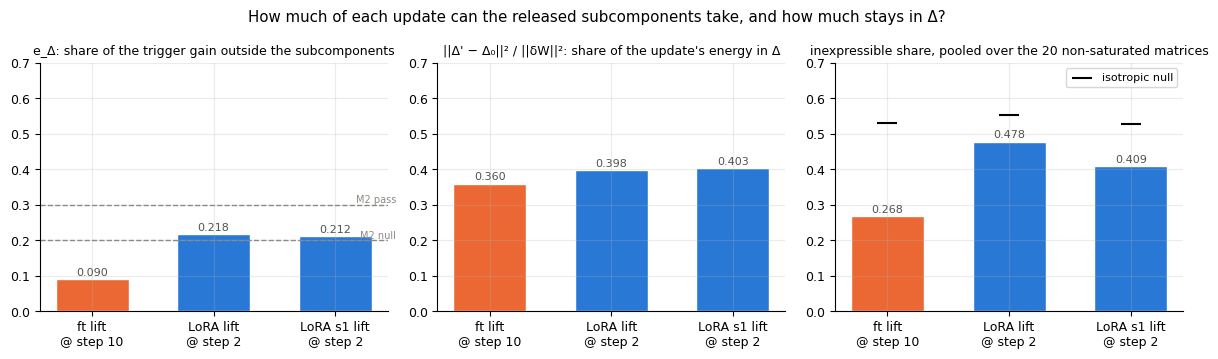

In [3]:
A = scored[~scored.arm.str.contains('nothing')].reset_index(drop=True)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
x = np.arange(len(A)); labels = [f'{a}\n@ step {s}' for a, s in zip(A.arm, A.step)]
cols = [C['orange'] if a.startswith('ft') else C['blue'] for a in A.arm]
for ax, k, title, lines in ((axes[0], 'e_delta', 'e_Δ: share of the trigger gain outside the subcomponents', [(0.2, 'M2 null'), (0.3, 'M2 pass')]),
                            (axes[1], 'Delta change', "||Δ' − Δ₀||² / ||δW||²: share of the update's energy in Δ", []),
                            (axes[2], 'inexpressible', 'inexpressible share, pooled over the 20 non-saturated matrices', [])):
    ax.bar(x, A[k], 0.6, color=cols, edgecolor='white')
    for i, v in enumerate(A[k]):
        ax.text(i, v + 0.01, f'{v:.3f}', ha='center', fontsize=8, color='#52514e')
    for y, lab in lines:
        ax.axhline(y, color=C['gray'], lw=1, ls='--'); ax.text(len(A) - 0.5, y, lab, ha='right', va='bottom', fontsize=7, color=C['gray'])
    ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_title(title, fontsize=9); ax.set_ylim(0, max(0.7, A[k].max() + 0.1))
axes[2].scatter(x, A['null'], marker='_', s=200, color='k', zorder=3, label='isotropic null'); axes[2].legend()
fig.suptitle('How much of each update can the released subcomponents take, and how much stays in Δ?'); plt.tight_layout(); plt.show()

In [4]:
# per matrix: where the energy sits and how much of it is inexpressible (LoRA at its scored step vs the fine-tune at step 10)
pl, pf = L0['steps'][str(L0['scored_step'])]['inexpressible']['per_matrix'], FT['measured']['inexpressible']['per_matrix']
keys = sorted(pf, key=lambda k: -pf[k]['energy_share'])
sat = [k for k in keys if k not in W0['non_saturated']]
PM = pd.DataFrame({'matrix': keys, 'saturated': [k in sat for k in keys],
                   'LoRA energy %': [100 * pl[k]['energy_share'] for k in keys], 'LoRA inexpressible': [pl[k]['omega_act'] for k in keys],
                   'ft energy %': [100 * pf[k]['energy_share'] for k in keys], 'ft inexpressible': [pf[k]['omega_act'] for k in keys],
                   'null': [pf[k]['null_act'] for k in keys], 'read_out': [pf[k]['read_out'] for k in keys]})
print(f"energy on the 4 saturated matrices: LoRA {PM[PM.saturated]['LoRA energy %'].sum():.0f}%, ft {PM[PM.saturated]['ft energy %'].sum():.0f}%")
for name, per in (('LoRA step 2', pl), ('ft step 10', pf), ('LoRA step 100', L0['steps']['100']['inexpressible']['per_matrix'])):
    e = sum(p['energy'] for p in per.values()); print(f'{name}: inexpressible share pooled over ALL 24 matrices {sum(p["omega_act"] * p["energy"] for p in per.values()) / e:.3f}')
PM.round(3)

energy on the 4 saturated matrices: LoRA 60%, ft 38%
LoRA step 2: inexpressible share pooled over ALL 24 matrices 0.193
ft step 10: inexpressible share pooled over ALL 24 matrices 0.165
LoRA step 100: inexpressible share pooled over ALL 24 matrices 0.442


,matrix,saturated,LoRA energy %,LoRA inexpressible,ft energy %,ft inexpressible,null,read_out
0,h.3.mlp.c_fc,True,45.392,0.000,22.035,0.000,0.000,0.000
1,h.2.mlp.c_fc,False,6.251,0.423,18.441,0.096,0.479,0.530
2,h.1.mlp.c_fc,False,7.778,0.507,13.456,0.177,0.538,0.586
3,h.0.mlp.c_fc,True,12.882,0.000,7.815,0.000,0.000,0.000
4,h.3.mlp.down_proj,True,1.107,0.000,5.490,0.000,0.000,0.463
5,h.3.attn.q_proj,False,5.355,0.685,4.120,0.551,0.841,0.882
6,h.3.attn.v_proj,False,3.680,0.268,3.261,0.259,0.460,0.680
7,h.2.mlp.down_proj,False,0.377,0.371,3.238,0.359,0.421,0.788
8,h.3.attn.k_proj,False,1.587,0.782,3.027,0.589,0.771,0.837
9,h.0.mlp.down_proj,True,0.329,0.000,2.885,0.000,0.000,0.621


**Could it do it?** Partly. The LoRA's lift leaves e_Δ 0.22 of the behaviour outside the subcomponents (seed 1: 0.21), between the one-site
LoRA's 0.33–0.43 (round 4) and the fine-tune's 0.09, with Δ taking 0.40 of the update's energy (fine-tune 0.36). GOALS fixes no number for
"Δ not absorbing δW", and this is more than twice what the fine-tune's lift leaves, so the second half of the weak version is an open
reading here, not a pass.

**Does it match the prediction?** M1 as predicted: pooled over the non-saturated matrices the LoRA's inexpressible share is 0.86 of the
isotropic null (0.478 / 0.553), because A has not moved from its random initialisation at step 2 (|cos| 1.000 on every matrix); round 4's
read-side finding holds on every matrix. M2 (e_Δ ≥ 0.3) is neither: what changed from round 4 is where the energy lands. 60% of the
LoRA's step-2 energy is on the four saturated matrices (45% on `h.3.mlp.c_fc`), where every update is expressible, against 38% of the
fine-tune's; pooled over all 24 matrices the two updates are equally inexpressible (0.19 and 0.17). The site, not the LoRA, was round 4's
obstacle.

## 3. Mechanism reading: which route does each arm's trigger gain take?

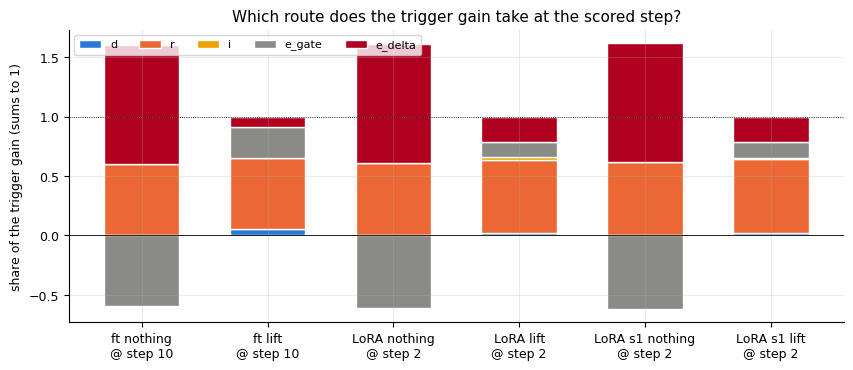

d: {'ft nothing @10': 0.0, 'ft lift @10': 0.052, 'LoRA nothing @2': 0.0, 'LoRA lift @2': 0.023, 'LoRA s1 nothing @2': 0.0, 'LoRA s1 lift @2': 0.024}


In [5]:
Rs = scored.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(Rs)); pos = np.zeros(len(Rs)); neg = np.zeros(len(Rs))
for k, col in (('d', C['blue']), ('r', C['orange']), ('i', C['yellow']), ('e_gate', C['gray']), ('e_delta', '#b00020')):
    v = Rs[k].values; base = np.where(v >= 0, pos, neg)
    ax.bar(x, v, 0.6, bottom=base, color=col, label=k, edgecolor='white', linewidth=1)
    pos += np.maximum(v, 0); neg += np.minimum(v, 0)
ax.axhline(0, color='k', lw=0.6); ax.axhline(1, color='k', lw=0.6, ls=':')
ax.set_xticks(x); ax.set_xticklabels([f'{a}\n@ step {s}' for a, s in zip(Rs.arm, Rs.step)])
ax.set_ylabel('share of the trigger gain (sums to 1)'); ax.set_title('Which route does the trigger gain take at the scored step?')
ax.legend(ncol=5, loc='upper left'); plt.show()
print('d:', dict(zip(Rs.arm + ' @' + Rs.step.astype(str), Rs.d.round(3))))

**Reading.** As in rounds 3 and 4: the changed subcomponents carry little for any arm (d 0.013–0.05; C1m, "flat within m = 0.1", passed as
predicted) and re-gating carries most of it (r 0.56–0.62). The LoRA do-nothing arm's e_gate = −r is the identity of the do-nothing
placement (its subcomponents are unchanged, so everything Γ re-gates is masked off again), not a finding.

## 4. Across training: the LoRA at step 2 and at step 100

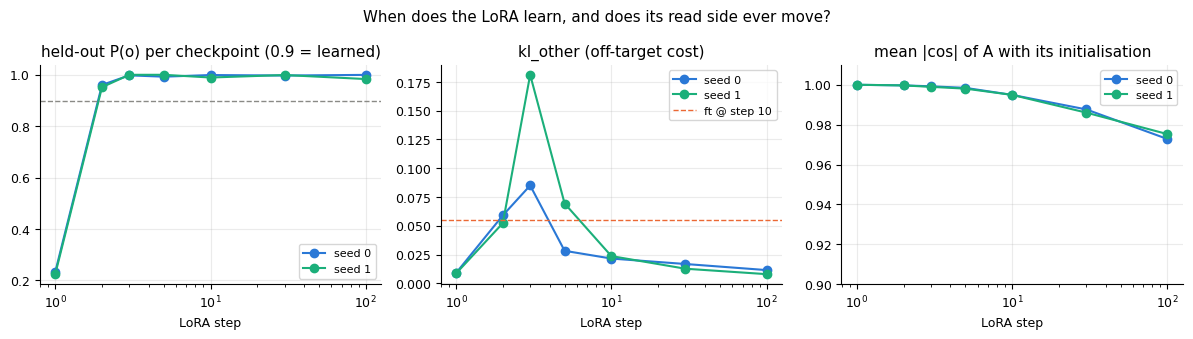

,arm,step,P(o),kl_other,gain,e_delta,Delta change,inexpressible,null,d,r,pile pgd_kl
1,ft lift,10,0.999,0.055,13.430,0.090,0.360,0.268,0.531,0.052,0.597,5.408
3,LoRA lift,2,0.961,0.059,9.738,0.218,0.398,0.478,0.553,0.023,0.608,1.128
5,LoRA lift,100,1.000,0.011,14.239,0.107,0.464,0.550,0.674,0.013,0.561,NaN
7,LoRA s1 lift,2,0.952,0.052,9.591,0.212,0.403,0.409,0.528,0.024,0.618,NaN
9,LoRA s1 lift,100,0.983,0.008,9.574,0.167,0.459,0.662,0.595,0.029,0.619,NaN


In [6]:
ck = sorted(L0['evals'], key=int)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for a, col, lab in ((L0, C['blue'], 'seed 0'), (L1, C['aqua'], 'seed 1')):
    st = [int(s) for s in ck]
    axes[0].plot(st, [a['evals'][s]['p_o'] for s in ck], 'o-', color=col, label=lab)
    axes[1].plot(st, [a['evals'][s]['kl_other'] for s in ck], 'o-', color=col, label=lab)
    axes[2].plot(st, [a['cos_init'][s]['mean'] for s in ck], 'o-', color=col, label=lab)
axes[0].axhline(0.9, color=C['gray'], ls='--', lw=1); axes[0].set_title('held-out P(o) per checkpoint (0.9 = learned)')
axes[1].axhline(FT['evals'][str(FT['step'])]['kl_other'], color=C['orange'], ls='--', lw=1, label='ft @ step 10'); axes[1].set_title('kl_other (off-target cost)')
axes[2].set_title("mean |cos| of A with its initialisation"); axes[2].set_ylim(0.9, 1.01)
for ax in axes: ax.set_xscale('log'); ax.set_xlabel('LoRA step'); ax.legend()
fig.suptitle('When does the LoRA learn, and does its read side ever move?'); plt.tight_layout(); plt.show()
T[T.arm.str.contains('lift')][['arm', 'step', 'P(o)', 'kl_other', 'gain', 'e_delta', 'Delta change', 'inexpressible', 'null', 'd', 'r', 'pile pgd_kl']].round(3)

**Reading.** The LoRA learns at step 2 and keeps P(o) ≥ 0.98 to step 100 while its off-target KL falls from 0.059 to 0.012. Its read side
barely moves even by step 100 (|cos| 0.973), yet two things change between step 2 and step 100: the energy moves off the saturated
matrices (inexpressible share over all 24 matrices 0.19 → 0.44, pooled over the non-saturated ones 0.48 → 0.55, with the null itself
rising to 0.67 because the energy mix changed) and e_Δ **falls** to 0.11 (seed 1: 0.17), close to the fine-tune's 0.09. Δ's share of the
update's energy rises (0.40 → 0.46). The step-100 lift carries no Pile measurement, so whether the faithfulness of section 1 survives the
LoRA's finished state is the one number this round leaves open.

## 5. Scores as filed, and which reading each bears on

In [7]:
verdict = lambda p: 'pass' if p['pass'] else ('null' if p['null'] else 'neither')
filed = {p['id'].split('_')[0]: p for p in pred['predictions']}
bears = {'M1': 'A (inexpressible)', 'M2': 'A (e_Δ)', 'C2m': 'A (faithfulness)', 'C1m': 'mechanism'}
out = []
for k in ('M1', 'M2', 'C2m', 'C1m'):
    p = SC[k]; f = filed[k]
    nums = {kk: (round(v, 3) if isinstance(v, float) else v) for kk, v in p.items() if kk not in ('pass', 'null', 'scored', 'conditions')}
    out.append({'id': f['id'], 'filed': f['predicted'].split(':')[0].split(',')[0], 'result': verdict(p), 'scored': p['scored'], 'bears on': bears[k], 'numbers': nums})
pd.DataFrame(out)

,id,filed,result,scored,bears on,numbers
0,M1_read_side_stays_random,pass,pass,True,A (inexpressible),"{'pooled': 0.478, 'pooled_null': 0.553, 'ratio..."
1,M2_lift_leaves_it_in_delta,pass,neither,True,A (e_Δ),{'e_delta': 0.218}
2,C2m_lora_lift_fragile_like_ft,pass,neither,True,A (faithfulness),"{'pgd_ft_lift': 5.408, 'pgd_lora_lift': 1.128,..."
3,C1m_direct_share_flat,pass,pass,True,mechanism,"{'d_ft_lift': 0.052, 'd_lora_lift': 0.023}"


## Summary

**What happened.** The LoRA learned the task (P(o) 0.96 at step 2, 1.00 at step 100). But its weight update does not commute
well. At the step it learns, the lift leaves 22% of the learned behaviour outside the subcomponents (e_Δ 0.22); the full fine-tune's
lift leaves 9%. On the 20 matrices the decomposition does not fully cover, the subcomponents can read the LoRA's update no better
than a random update (inexpressible share 0.86 of the random null). By step 100 the behaviour gap closes (e_Δ 0.11 against 0.09)
but the energy gap widens (46% of the update's energy in Δ against 36%; inexpressible share 0.55 against 0.27). So the LoRA
commutes no better than the fine-tune, and by the energy measure worse.

**Why.** A LoRA's update is B·A. A picks the input directions the update reads. A is initialised at random and barely trains
(|cos| with its initialisation 1.000 at step 2, 0.973 at step 100). Each VPD subcomponent reads one fixed input direction, and a
random direction lies mostly outside the span of those, so no change to the existing subcomponents can express it. The four
saturated matrices are the exception: their subcomponents span every direction, so anything is expressible there. 60% of the
LoRA's step-2 energy happens to land on them, which is the only reason this round beat round 4's one-matrix LoRA (e_Δ 0.33–0.43).
As training goes on the energy moves to the poorly covered matrices and the inexpressible share rises.

**The one good number is not trusted yet.** The lifted LoRA decomposition passed the Pile adversarial check (PGD ratio 1.13, at the
W₀ floor) where the fine-tune's lift failed (5.41). But the LoRA was scored at step 2, where the update is so small that leaving
all of it in Δ also passes (do-nothing 1.17). The fine-tune's lift passed at its own step 1 too (1.14, round 2) and only failed by
step 10. The LoRA lift's Pile numbers at steps 10 and 100 were not measured, so this is not evidence that a LoRA's lift survives
where the fine-tune's does not.

**What would fix it** (candidates; each needs `/design` and filed predictions before it runs):

1. **First, measure the missing Pile numbers**: LoRA lift at steps 10 and 100, fine-tune lift at steps 1–3. Five minutes on the
   cluster. This decides whether the faithfulness advantage is real.
2. **Give the LoRA a read side the decomposition can read.** Initialise each matrix's A inside the span of its alive
   subcomponents' read vectors (the read-side LoRA, review section 3.1). The review dropped it for the one-matrix site because the
   pull-back there was expressible yet still fragile. It also said that if M1 came out near the null on the well-covered matrices,
   the read-side LoRA on all 24 matrices is no longer ruled out by that result. M1 did.
3. **Let A become data-shaped.** With a data-shaped read side (the fine-tune's own update) the inexpressible share is 0.27; the
   LoRA's is 0.48–0.55. At lr 1e-3 A moved 3% in 100 steps, so this needs a higher learning rate on A, not more steps, and it may
   just reproduce the fine-tune's numbers.
4. **The per-step lift with updated bases** (review section 3.3): lift each step and rotate the subcomponents' read span towards
   A, so later steps become expressible. Its tolerance rule has to be decided first.

**Predictions as filed.** M1 pass, C1m pass. M2 neither (e_Δ 0.22, between the 0.2 null and the 0.3 pass line). C2m neither
and reversed in direction: filed as "the LoRA lift is fragile like the fine-tune's, PGD ≥ 5"; it read 1.13, and the null
(≤ 2 with e_Δ ≤ 0.2) is missed only by e_Δ 0.018.
